# RETO APRENDIZAJE SUPERVISADO

## 1. CARGA DE ARCHIVOS

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv('/content/gdrive/MyDrive/Diplomado Data Science/Machine Learning/Aprendizaje supervisado/bank_marketing_RETO_DS_AS.csv')
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,31,self-employed,married,tertiary,no,2666,no,no,cellular,10,nov,318,2,97,6,success,yes
1,29,unemployed,single,unknown,no,1584,no,no,cellular,6,sep,245,1,-1,0,unknown,yes
2,41,blue-collar,married,secondary,no,2152,yes,no,cellular,17,nov,369,1,-1,0,unknown,no
3,50,blue-collar,married,secondary,no,84,yes,no,cellular,17,jul,18,8,-1,0,unknown,no
4,40,admin.,married,secondary,no,0,no,no,cellular,28,jul,496,2,182,11,success,yes


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        9000 non-null   int64 
 1   job        9000 non-null   object
 2   marital    9000 non-null   object
 3   education  9000 non-null   object
 4   default    9000 non-null   object
 5   balance    9000 non-null   int64 
 6   housing    9000 non-null   object
 7   loan       9000 non-null   object
 8   contact    9000 non-null   object
 9   day        9000 non-null   int64 
 10  month      9000 non-null   object
 11  duration   9000 non-null   int64 
 12  campaign   9000 non-null   int64 
 13  pdays      9000 non-null   int64 
 14  previous   9000 non-null   int64 
 15  poutcome   9000 non-null   object
 16  y          9000 non-null   object
dtypes: int64(7), object(10)
memory usage: 1.2+ MB


In [ ]:
data.shape

(9000, 17)

In [ ]:
data.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


In [ ]:
data.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [ ]:
data.describe()

,age,balance,day,duration,campaign,pdays,previous
count,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000
mean,41.090556,1482.262778,15.619556,353.832778,2.520111,50.511333,0.788889
std,11.664253,3031.013197,8.345305,336.945158,2.737758,107.691963,2.210273
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,109.000000,8.000000,131.000000,1.000000,-1.000000,0.000000
50%,39.000000,519.000000,15.000000,240.500000,2.000000,-1.000000,0.000000
75%,49.000000,1646.500000,21.000000,462.000000,3.000000,-1.000000,0.000000
max,95.000000,81204.000000,31.000000,3253.000000,58.000000,850.000000,58.000000


In [ ]:
# Listas de columnas por tipo
cat_cols = data.select_dtypes(include='object').columns.tolist()
num_cols = data.select_dtypes(include='int64').columns.tolist()

# Quita la variable de salida de las categóricas
cat_cols.remove('y')

print('Categóricas de entrada:', len(cat_cols), cat_cols)
print('Numéricas de entrada:', len(num_cols), num_cols)

Categóricas de entrada: 9 ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numéricas de entrada: 7 ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [ ]:
# A pesar de tener no valores null, aparecen valores que son unknown por el arrchivo que se considera como null

for col in cat_cols:
    print(data[col].value_counts(), '\n')

job
management       1999
blue-collar      1688
technician       1485
admin.           1004
services          771
retired           594
self-employed     319
student           312
unemployed        290
housemaid         246
entrepreneur      241
unknown            51
Name: count, dtype: int64 

marital
married     5124
single      2837
divorced    1039
Name: count, dtype: int64 

education
secondary    4486
tertiary     2893
primary      1244
unknown       377
Name: count, dtype: int64 

default
no     8865
yes     135
Name: count, dtype: int64 

housing
no     4564
yes    4436
Name: count, dtype: int64 

loan
no     7820
yes    1180
Name: count, dtype: int64 

contact
cellular     6438
unknown      1982
telephone     580
Name: count, dtype: int64 

month
may    2361
jul    1287
aug    1227
jun    1023
nov     723
apr     707
feb     557
oct     293
jan     289
sep     234
mar     208
dec      91
Name: count, dtype: int64 

poutcome
unknown    6783
failure    1006
success     770
other

In [ ]:
# Para contar unkown por fila se realiza el siguiente codigo

unknown = (data == 'unknown').sum()
unknown[unknown > 0]

,0
job,51
education,377
contact,1982
poutcome,6783


In [ ]:
# Para coontar los valores -1 de pdays

(data['pdays'] == -1).sum()

np.int64(6781)

y
no     5213
yes    3787
Name: count, dtype: int64
y
no     0.579222
yes    0.420778
Name: proportion, dtype: float64


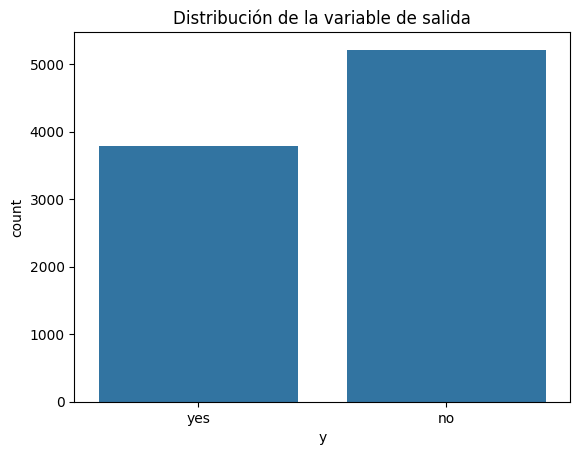

In [ ]:
# Se hara un analisis de las variables de salida, para saber cuantos yes y cuantos no hay

#Para medirlo gr
print(data['y'].value_counts())
print(data['y'].value_counts(normalize= True))

sns.countplot(x='y', data=data)
plt.title('Distribución de la variable de salida')
plt.show()

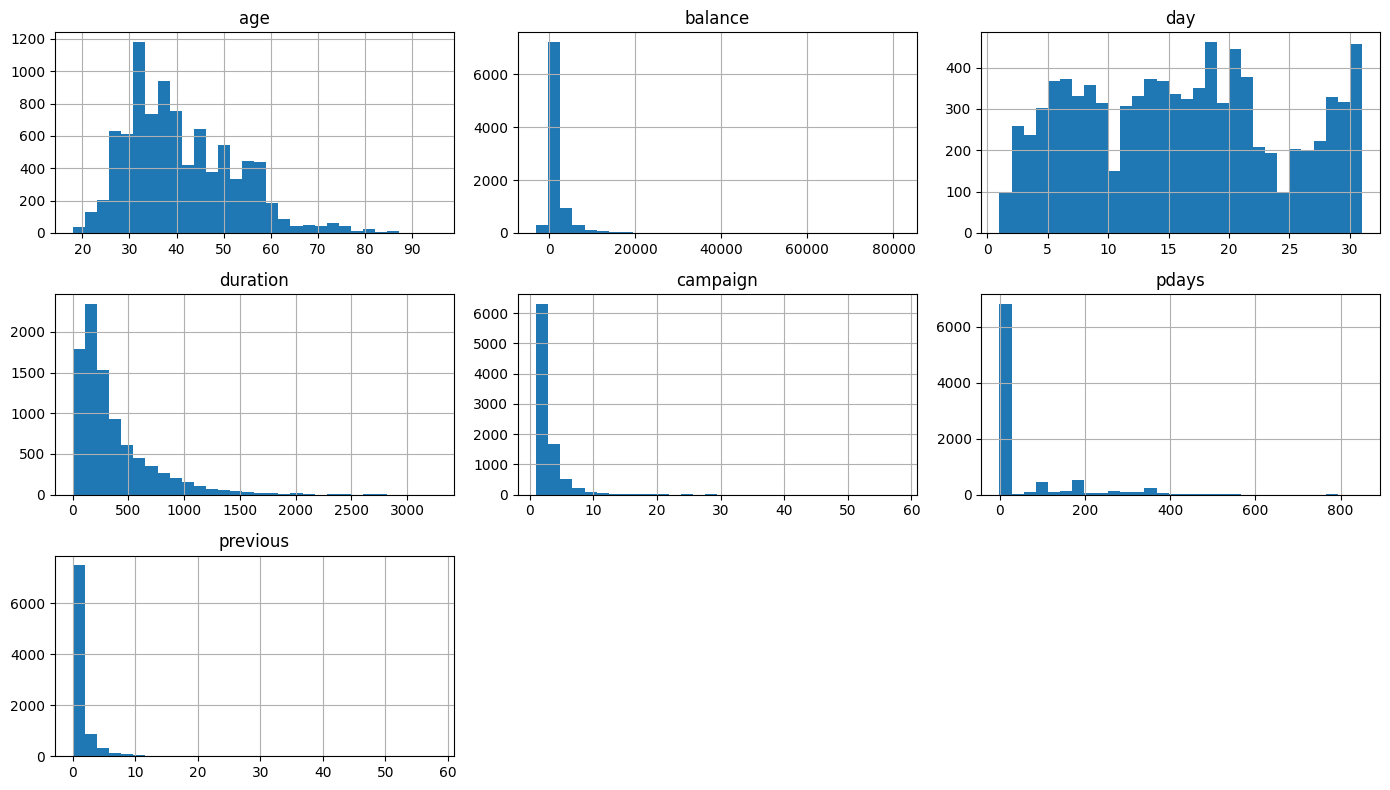

In [ ]:
# Para medir que tan cargada esta la distribución hacia que lado y distinguir si existe un sesgo positivo o negativo

data[num_cols].hist(figsize=(14, 8), bins=30)
plt.tight_layout()
plt.show()

In [ ]:
data[num_cols].skew()

,0
age,0.801429
balance,7.280036
day,0.117315
duration,2.184045
campaign,5.392712
pdays,2.349177
previous,7.682286


### Conclusiones del análisis descriptivo

- El conjunto tiene 9,000 registros y 17 columnas.
- Variables de entrada: 7 numéricas (age, balance, day, duration, campaign, pdays, previous) y 9 categóricas (job, marital, education, default, housing, loan, contact, month, poutcome).
- Variable de salida: `y` (binaria: yes / no).
- **Datos perdidos:** no hay valores nulos (NaN), pero sí valores "unknown" en job (0.6%), education (4.2%), contact (22%) y poutcome (75.4%).
- **pdays y poutcome:** los 6,781 registros con `pdays = -1` coinciden con `previous = 0` y `poutcome = "unknown"`. Son clientes que no habían sido contactados en campañas anteriores, por lo que en `poutcome` el valor "unknown" no es un dato perdido, sino la información de que no hubo campaña previa.
- **Decisión sobre los "unknown":**
  - `job` (0.6%) y `education` (4.2%): se reemplazarán por la moda de cada columna, ya que son pocos registros y el impacto es mínimo.
  - `contact` (22%): se conservará "unknown" como una categoría más, porque rellenar con la moda implicaría inventar el dato de casi 2,000 clientes.
  - `poutcome` (75.4%): se conservará "unknown" como categoría, ya que representa a los clientes sin campaña previa. Eliminar estos registros significaría perder tres cuartas partes de los datos.
- **Balance de clases:** 58% "no" y 42% "yes", por lo que la muestra está razonablemente balanceada.
- **Sesgo:** las variables balance, duration, campaign, pdays y previous presentan sesgo positivo fuerte (skew > 1) y se transformarán en el siguiente paso.


In [ ]:
data_t = data.copy()

# Se rellenan los "unknown" de job y education con la moda de cada variable (sin contar "unknown")
for col in ['job', 'education']:
    moda = data_t.loc[data_t[col] != 'unknown', col].mode()[0]
    data_t[col] = data_t[col].replace('unknown', moda)
    print(col, '-> moda:', moda)

# Se comprueba que ya no quedan valores "unknown"
(data_t[['job', 'education']] == 'unknown').sum()

job -> moda: management
education -> moda: secondary


,0
job,0
education,0


In [ ]:
# En las variables binarias de default, housing, loan y la salida se convertiran en
# 1 para yes y 0 para no

binarias = ['default', 'housing', 'loan', 'y']

for col in binarias:
  data_t[col] = data_t[col].map({'yes': 1, 'no': 0})

data_t[binarias].head()

,default,housing,loan,y
0,0,0,0,1
1,0,0,0,1
2,0,1,0,0
3,0,1,0,0
4,0,0,0,1


### LabelEncoder vs OneHotEncoder

Para las variables categóricas con más de dos opciones (job, marital, education, contact, month y poutcome) se utilizará **OneHotEncoder** (con `pd.get_dummies`).

**LabelEncoder** asigna un número entero a cada categoría (por ejemplo, admin. = 0, blue-collar = 1, student = 8). El problema es que los modelos interpretan esos números como cantidades: entenderían que "student" es mayor que "admin." o que existe una distancia entre categorías, relaciones que no existen. Esto afecta especialmente a la regresión logística y a la red neuronal, que multiplican cada variable por un peso.

**OneHotEncoder** crea una columna binaria (0/1) por cada categoría, por lo que no introduce ningún orden ni distancia artificial. Aunque `education` tiene un orden natural (primary < secondary < tertiary), se aplicó OneHotEncoder a todas las variables por consistencia.

Se usa `drop_first=True` para eliminar una columna por variable y evitar información redundante: si una variable tiene 3 categorías, con 2 columnas es suficiente para representarla.

In [ ]:
multi = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
data_t = pd.get_dummies(data_t, columns=multi, drop_first=True, dtype=int)

# drop_first elimina una columna por variable: si marital tiene 3 opciones, se queda con 2
data_t.shape

(9000, 41)

### Corrección del sesgo

Se aplicará la transformación logarítmica a las variables con sesgo positivo fuerte (balance, duration, campaign, pdays y previous). Antes se revisa el mínimo de cada una, ya que el logaritmo no acepta ceros ni valores negativos.

In [ ]:
sesgo_cols = ['balance', 'duration', 'campaign', 'pdays', 'previous']
data_t[sesgo_cols].min()

,0
balance,-3058
duration,3
campaign,1
pdays,-1
previous,0


In [ ]:
# Revision del sesgo
print('Antes:\n', data_t[['balance', 'duration', 'campaign', 'pdays', 'previous']].skew(), '\n')

for col in ['duration', 'campaign', 'previous']:
  data_t[col] = np.log1p(data_t[col])

data_t['pdays'] = np.log(data['pdays'] + 1)
data_t['balance'] = np.log(data_t[['balance', 'duration', 'campaign','pdays', 'previous']].skew())

Antes:
 balance     7.280036
duration    2.184045
campaign    5.392712
pdays       2.349177
previous    7.682286
dtype: float64 

Después:
 balance     0.734873
duration   -0.449303
campaign    1.396806
pdays       1.247108
previous    1.956485
dtype: float64


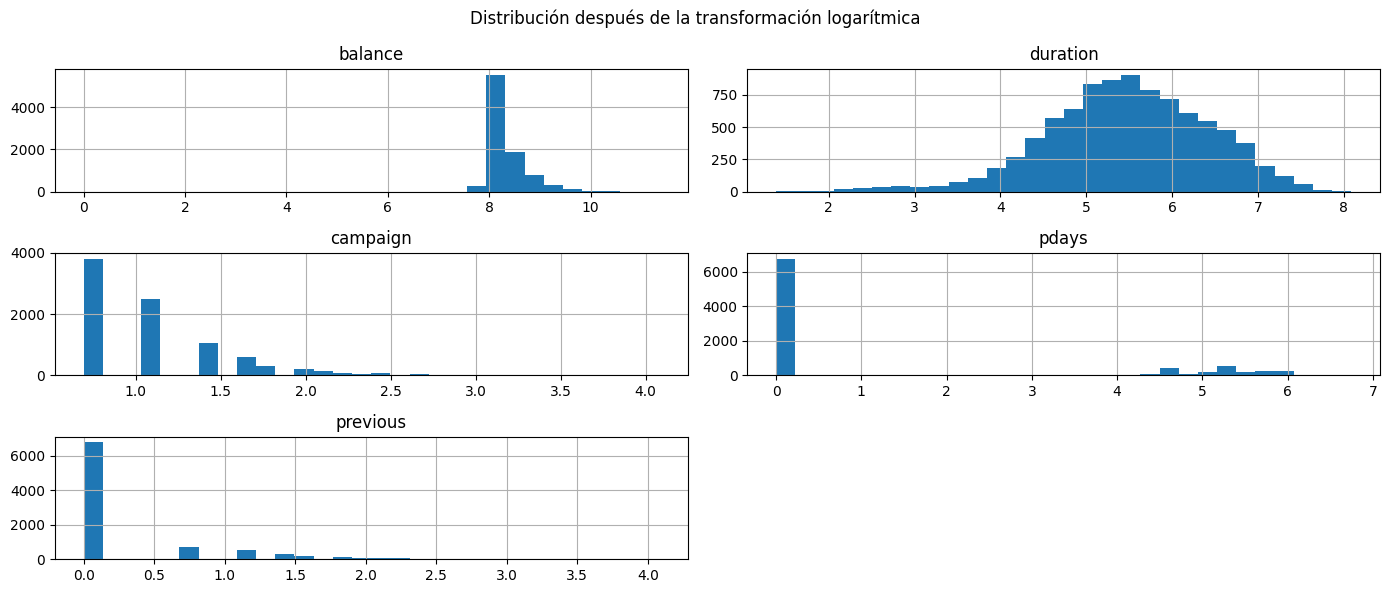

In [ ]:
data_t[sesgo_cols].hist(figsize=(14, 6), bins=30)
plt.suptitle('Distribución después de la transformación logarítmica')
plt.tight_layout()
plt.show()

### Escalamiento

Después del logaritmo, las variables numéricas siguen en escalas muy distintas (por ejemplo, age va de 18 a 95 y day de 1 a 31), mientras que las variables dummies valen 0 o 1. La regresión logística y la red neuronal aprenden mejor cuando las variables están en escalas parecidas; con escalas muy diferentes, la red neuronal puede tardar más o entrenar de forma incorrecta. Por eso se aplica la estandarización (media 0 y desviación estándar 1) a las 7 variables numéricas. Las binarias y las dummies no se escalan porque ya están en 0/1.


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_t[num_cols] = scaler.fit_transform(data_t[num_cols])

data_t[num_cols].describe().round(2)

,age,balance,day,duration,campaign,pdays,previous
count,9000.00,9000.00,9000.00,9000.00,9000.00,9000.00,9000.00
mean,0.00,0.00,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.98,-20.85,-1.75,-4.28,-0.87,-0.56,-0.51
25%,-0.78,-0.65,-0.91,-0.61,-0.87,-0.56,-0.51
50%,-0.18,-0.34,-0.07,0.02,-0.03,-0.56,-0.51
75%,0.68,0.34,0.64,0.70,0.57,-0.56,-0.51
max,4.62,7.57,1.84,2.75,6.17,2.43,6.23


### Conclusiones de la transformación de variables

- **Datos "unknown":** en `job` y `education` se reemplazaron por la moda (management y secondary). En `contact` y `poutcome` se conservaron como una categoría más.
- **Variables binarias:** `default`, `housing`, `loan` y la salida `y` se convirtieron a 1 (yes) y 0 (no).
- **Variables categóricas:** se aplicó OneHotEncoder con `drop_first=True` a job, marital, education, contact, month y poutcome, para no introducir un orden artificial entre categorías.
- **Sesgo:** se aplicó logaritmo a balance, duration, campaign, pdays y previous. En `pdays` (mínimo -1) y `balance` (valores negativos) primero se trasladaron los datos para que el mínimo quedara en 1.
  - `balance` bajó su sesgo de 7.28 a 0.73 y `duration` de 2.18 a -0.45, quedando aproximadamente simétricas.
  - `campaign` (1.40), `pdays` (1.25) y `previous` (1.96) mejoraron, pero siguen por arriba de 1. Esto se debe a que la mayoría de los clientes comparten el mismo valor (por ejemplo, el 75% no tuvo contactos previos): el logaritmo comprime la cola larga, pero no puede repartir una gran concentración de valores idénticos.
  - En `balance`, los pocos clientes con saldo muy negativo quedaron alejados del resto (mínimo de -20.85 después de estandarizar).
- **Escalamiento:** las 7 variables numéricas se estandarizaron con media 0 y desviación estándar 1.
- **Resultado final:** el conjunto transformado tiene 9,000 registros y 41 columnas (40 variables de entrada y la variable de salida `y`).

## 3. Partición de los datos

### Separación de entradas (X) y salida (y)

El modelo necesita recibir por separado las variables que usa para predecir (X) y la variable que debe predecir (y). Se toma `y` como variable de salida y el resto de las columnas como variables de entrada.

In [ ]:
X = data_t.drop(columns='y')
y = data_t['y']

print('X:', X.shape)
print('y:', y.shape)

X: (9000, 40)
y: (9000,)


### Conjuntos de entrenamiento, validación y prueba (60% / 20% / 20%)

`train_test_split` solo divide los datos en dos partes a la vez, por lo que la partición se hace en dos pasos:
1. Se separa el 60% para entrenamiento y se aparta el 40% restante.
2. Ese 40% se divide a la mitad: 20% para validación y 20% para prueba.

Se usa `stratify` para conservar la misma proporción de "yes" y "no" en los tres conjuntos, y `random_state=42` para que la partición sea igual cada vez que se ejecute el notebook.

In [ ]:
from sklearn.model_selection import train_test_split

# Paso 1: 60% entrenamiento, 40% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)

# Paso 2: el 40% temporal se divide a la mitad: 20% validación y 20% prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

### Verificacion tamaños y proporciones

In [ ]:
total = len(X)
for nombre, Xs, ys in [('Entrenamiento', X_train, y_train),
                       ('Validación', X_val, y_val),
                       ('Prueba', X_test, y_test)]:
    print(f'{nombre}: {len(Xs)} registros ({len(Xs)/total:.0%}) | proporción de yes: {ys.mean():.2%}')

Entrenamiento: 5400 registros (60%) | proporción de yes: 42.07%
Validación: 1800 registros (20%) | proporción de yes: 42.11%
Prueba: 1800 registros (20%) | proporción de yes: 42.06%


### Conclusiones de la partición

- Los datos se dividieron en tres conjuntos: entrenamiento con 5,400 registros (60%), validación con 1,800 (20%) y prueba con 1,800 (20%).
- Gracias a `stratify`, los tres conjuntos conservan aproximadamente la misma proporción de clientes que adquieren el plan (~42% "yes"), lo que permite comparar los modelos de forma justa.
- **Entrenamiento:** se usa para que cada modelo ajuste sus pesos minimizando la función de costo.
- **Validación:** se usa para comparar modelos y ajustar sus hiperparámetros.
- **Prueba:** se usa una sola vez al final, con el mejor modelo, para medir qué tan bien generaliza con datos que nunca vio.

## 4. Modelo 1: Regresión Logística

Se entrena el modelo con el conjunto de entrenamiento y se valida con el conjunto de validación. Primero se prueba un modelo base con los parámetros por defecto y después se ajustan sus hiperparámetros para buscar el mejor resultado.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

def evaluar (modelo, X_eval, y_eval, titulo):
  """Imprime la exactitud y el reporte de calificación, y grafica la matriz de confusión"""
  pred = modelo.predict(X_eval)
  print(f'{titulo}\nExactitud: {accuracy_score(y_eval, pred):.2%}\n')
  print(classification_report(y_eval, pred,target_names=['No (0)', 'Sí (1)']))
  ConfusionMatrixDisplay(confusion_matrix(y_eval, pred), display_labels=['No (0)', 'Sí (1)']).plot(cmap='Blues')

  plt.title(titulo)
  plt.show()

### 4.1 Modelo base

Se entrena una regresión logística con los parámetros por defecto (penalización L2 y C = 1) como punto de partida.

Exactitud en entrenamiento: 83.11%
Regresión logística base - Validación
Exactitud: 82.67%

              precision    recall  f1-score   support

      No (0)       0.85      0.86      0.85      1042
      Sí (1)       0.80      0.78      0.79       758

    accuracy                           0.83      1800
   macro avg       0.82      0.82      0.82      1800
weighted avg       0.83      0.83      0.83      1800



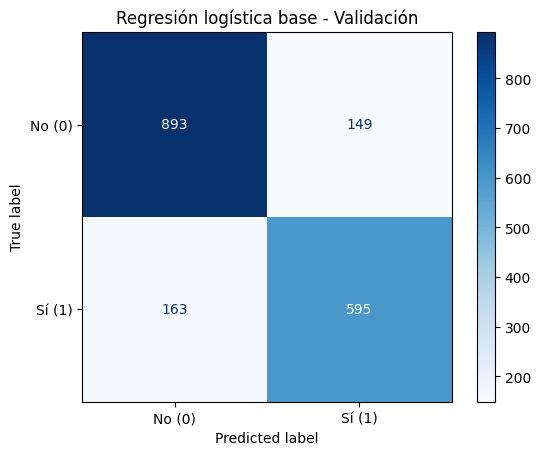

In [ ]:
lr_base = LogisticRegression(max_iter=1000, random_state=42)
lr_base.fit(X_train, y_train)

print(f'Exactitud en entrenamiento: {accuracy_score(y_train, lr_base.predict(X_train)):.2%}')
evaluar(lr_base, X_val, y_val, 'Regresión logística base - Validación')

### 4.2 Ajuste de hiperparámetros

Se prueban combinaciones de tres hiperparámetros y se comparan con el conjunto de validación:

- **penalty (L1 o L2):** tipo de regularización, que ayuda a evitar el sobreentrenamiento castigando los coeficientes grandes.
- **C:** controla la fuerza de la regularización. Un C más pequeño significa más regularización.
- **class_weight:** con `'balanced'`, el modelo da más peso a la clase minoritaria ("yes", 42%), para no favorecer a la clase mayoritaria.

Se usa el solver `liblinear` porque admite tanto L1 como L2.

In [ ]:
from sklearn.metrics import recall_score, f1_score

resultados = []
for penalty in ['l1', 'l2']:
    for C in [0.01, 0.1, 1, 10]:
        for class_weight in [None, 'balanced']:
            modelo = LogisticRegression(penalty=penalty, C=C, class_weight=class_weight,
                                        solver='liblinear', max_iter=1000, random_state=42)
            modelo.fit(X_train, y_train)
            pred_val = modelo.predict(X_val)
            resultados.append({
                'penalty': penalty,
                'C': C,
                'class_weight': str(class_weight),
                'exactitud_train': accuracy_score(y_train, modelo.predict(X_train)),
                'exactitud_val': accuracy_score(y_val, pred_val),
                'recall_val': recall_score(y_val, pred_val),
                'f1_val': f1_score(y_val, pred_val)
            })

tabla_lr = pd.DataFrame(resultados).sort_values(['exactitud_val', 'f1_val'], ascending=False)
tabla_lr.round(4).head(10)

,penalty,C,class_weight,exactitud_train,exactitud_val,recall_val,f1_val
5,l1,1.00,balanced,0.8289,0.8356,0.8509,0.8134
13,l2,1.00,balanced,0.8281,0.8339,0.8496,0.8116
7,l1,10.00,balanced,0.8281,0.8328,0.8483,0.8103
15,l2,10.00,balanced,0.8283,0.8322,0.8483,0.8098
11,l2,0.10,balanced,0.8257,0.8300,0.8509,0.8083
3,l1,0.10,balanced,0.8267,0.8300,0.8496,0.8080
10,l2,0.10,None,0.8280,0.8272,0.7863,0.7931
12,l2,1.00,None,0.8313,0.8267,0.7850,0.7923
2,l1,0.10,None,0.8246,0.8267,0.7810,0.7914
9,l2,0.01,balanced,0.8157,0.8256,0.8562,0.8052


### 4.3 Mejor modelo de regresión logística

Se entrena nuevamente el modelo con la combinación de hiperparámetros que obtuvo la mayor exactitud en validación.

Mejores hiperparámetros: {'penalty': 'l1', 'C': 1.0, 'class_weight': 'balanced'}
Exactitud en entrenamiento: 82.89%
Mejor regresión logística - Validación
Exactitud: 83.56%

              precision    recall  f1-score   support

      No (0)       0.88      0.82      0.85      1042
      Sí (1)       0.78      0.85      0.81       758

    accuracy                           0.84      1800
   macro avg       0.83      0.84      0.83      1800
weighted avg       0.84      0.84      0.84      1800



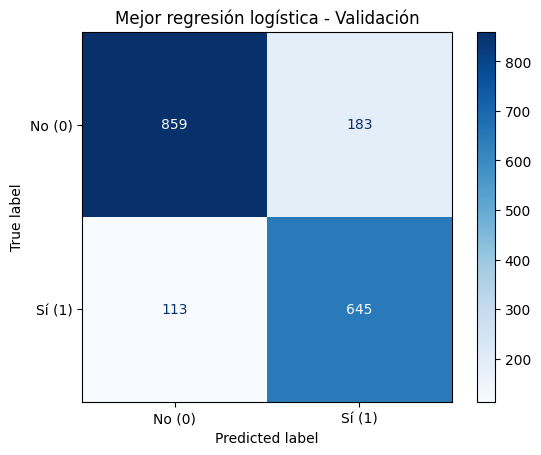

In [ ]:
mejor = tabla_lr.iloc[0]
print('Mejores hiperparámetros:', mejor[['penalty', 'C', 'class_weight']].to_dict())

mejor_lr = LogisticRegression(penalty=mejor['penalty'], C=mejor['C'],
                              class_weight=None if mejor['class_weight'] == 'None' else 'balanced',
                              solver='liblinear', max_iter=1000, random_state=42)
mejor_lr.fit(X_train, y_train)

print(f'Exactitud en entrenamiento: {accuracy_score(y_train, mejor_lr.predict(X_train)):.2%}')
evaluar(mejor_lr, X_val, y_val, 'Mejor regresión logística - Validación')

### Conclusiones de la regresión logística

- **Modelo base** (L2, C = 1): exactitud de 82.67% en validación. Detectó el 78.5% de los clientes que sí adquirieron el plan (recall).
- **Mejor modelo** (L1, C = 1, class_weight = 'balanced'): exactitud de **83.56%** en validación.
- La mejora principal vino de `class_weight='balanced'`: el recall de la clase "Sí" subió de 78.5% a **85.1%**. Es decir, el modelo encuentra más clientes interesados en el plan, que es lo más valioso para la campaña de telemarketing.
- **Matriz de confusión en validación:** 859 verdaderos negativos, 645 verdaderos positivos, 183 falsos positivos (clientes llamados que no compraron) y 113 falsos negativos (clientes interesados que el modelo no detectó).
- La exactitud en entrenamiento (82.89%) y en validación (83.56%) es muy similar, por lo que el modelo **no presenta sobreentrenamiento**.
- El valor de C tuvo poco efecto entre 0.1 y 10; solo con C = 0.01 (demasiada regularización) el desempeño bajó.

## 5. Modelo 2: Red Neuronal

Se utiliza `MLPClassifier` de scikit-learn, una red neuronal de tipo perceptrón multicapa. Se entrena con el conjunto de entrenamiento y se valida con el conjunto de validación. Primero se prueba un modelo base y después se ajustan sus hiperparámetros, entre ellos el número de capas ocultas y de neuronas.

### 5.1 Modelo base

Se entrena una red con los parámetros por defecto: una capa oculta de 100 neuronas, activación ReLU y alpha = 0.0001.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Exactitud en entrenamiento: 99.85%
Red neuronal base - Validación
Exactitud: 83.00%

              precision    recall  f1-score   support

      No (0)       0.86      0.84      0.85      1042
      Sí (1)       0.79      0.81      0.80       758

    accuracy                           0.83      1800
   macro avg       0.83      0.83      0.83      1800
weighted avg       0.83      0.83      0.83      1800



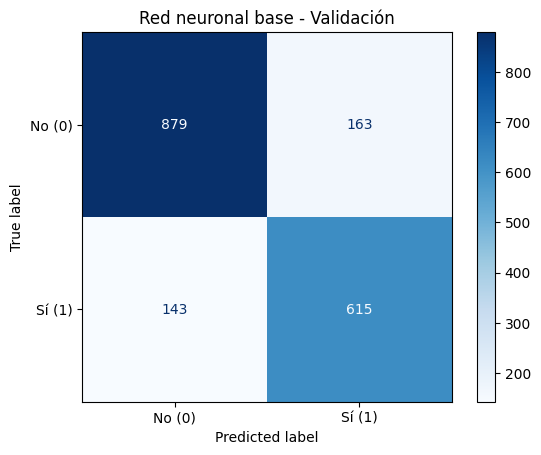

In [ ]:
from sklearn.neural_network import MLPClassifier

nn_base = MLPClassifier(max_iter=1000, random_state=42)
nn_base.fit(X_train, y_train)

print(f'Exactitud en entrenamiento: {accuracy_score(y_train, nn_base.predict(X_train)):.2%}')
evaluar(nn_base, X_val, y_val, 'Red neuronal base - Validación')

### 5.2 Ajuste de hiperparámetros

Se prueban combinaciones de tres hiperparámetros y se comparan con el conjunto de validación:

- **hidden_layer_sizes:** número de capas ocultas y de neuronas en cada una. Por ejemplo, `(10,)` es una capa de 10 neuronas y `(20, 10)` son dos capas de 20 y 10 neuronas.
- **activation:** función de activación de las neuronas ocultas (`relu` o `tanh`).
- **alpha:** fuerza de la regularización L2. Un valor más grande castiga más los pesos grandes y ayuda a evitar el sobreentrenamiento.

Además, se activa `early_stopping=True`: la red aparta internamente una parte del entrenamiento y deja de entrenar cuando ya no mejora, lo que también ayuda a evitar el sobreentrenamiento.

In [ ]:
resultados_nn = []
for capas in [(5,), (10,), (20,), (50,), (10, 5), (20, 10), (50, 25)]:
    for activation in ['relu', 'tanh']:
        for alpha in [0.0001, 0.01, 1]:
            modelo = MLPClassifier(hidden_layer_sizes=capas, activation=activation, alpha=alpha,
                                   early_stopping=True, max_iter=1000, random_state=42)
            modelo.fit(X_train, y_train)
            pred_val = modelo.predict(X_val)
            resultados_nn.append({
                'capas': capas,
                'activation': activation,
                'alpha': alpha,
                'exactitud_train': accuracy_score(y_train, modelo.predict(X_train)),
                'exactitud_val': accuracy_score(y_val, pred_val),
                'recall_val': recall_score(y_val, pred_val),
                'f1_val': f1_score(y_val, pred_val)
            })

tabla_nn = pd.DataFrame(resultados_nn).sort_values(['exactitud_val', 'f1_val'], ascending=False)
tabla_nn.round(4).head(10)

,capas,activation,alpha,exactitud_train,exactitud_val,recall_val,f1_val
37,"(50, 25)",relu,0.0100,0.8719,0.8422,0.8166,0.8134
27,"(10, 5)",tanh,0.0001,0.8594,0.8417,0.8443,0.8179
25,"(10, 5)",relu,0.0100,0.8509,0.8417,0.8245,0.8143
36,"(50, 25)",relu,0.0001,0.8822,0.8417,0.8232,0.8141
20,"(50,)",relu,1.0000,0.8431,0.8417,0.8219,0.8138
19,"(50,)",relu,0.0100,0.8507,0.8406,0.7982,0.8083
28,"(10, 5)",tanh,0.0100,0.8485,0.8400,0.8404,0.8156
38,"(50, 25)",relu,1.0000,0.8548,0.8394,0.8364,0.8144
31,"(20, 10)",relu,0.0100,0.8515,0.8394,0.8351,0.8141
33,"(20, 10)",tanh,0.0001,0.8383,0.8389,0.8443,0.8153


### 5.3 Mejor modelo de red neuronal

Se entrena nuevamente la red con la combinación de hiperparámetros que obtuvo la mayor exactitud en validación.

Mejores hiperparámetros: {'capas': (50, 25), 'activation': 'relu', 'alpha': 0.01}
Exactitud en entrenamiento: 87.19%
Mejor red neuronal - Validación
Exactitud: 84.22%

              precision    recall  f1-score   support

      No (0)       0.87      0.86      0.86      1042
      Sí (1)       0.81      0.82      0.81       758

    accuracy                           0.84      1800
   macro avg       0.84      0.84      0.84      1800
weighted avg       0.84      0.84      0.84      1800



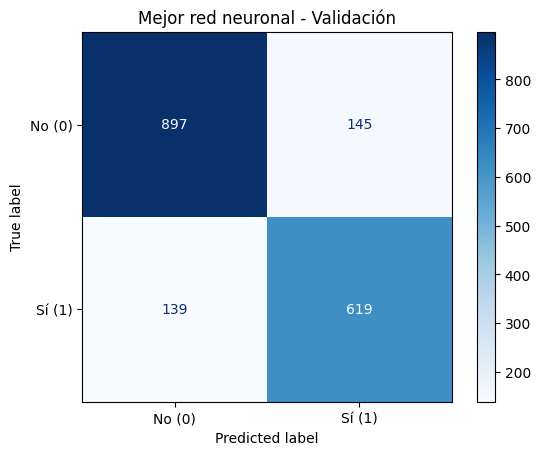

In [ ]:
mejor_nn_params = tabla_nn.iloc[0]
print('Mejores hiperparámetros:', mejor_nn_params[['capas', 'activation', 'alpha']].to_dict())

mejor_nn = MLPClassifier(hidden_layer_sizes=mejor_nn_params['capas'],
                         activation=mejor_nn_params['activation'],
                         alpha=mejor_nn_params['alpha'],
                         early_stopping=True, max_iter=1000, random_state=42)
mejor_nn.fit(X_train, y_train)

print(f'Exactitud en entrenamiento: {accuracy_score(y_train, mejor_nn.predict(X_train)):.2%}')
evaluar(mejor_nn, X_val, y_val, 'Mejor red neuronal - Validación')

### Conclusiones de la red neuronal

- **Modelo base** (1 capa de 100 neuronas): exactitud de **99.85% en entrenamiento**, pero solo **83.00% en validación**. Esa diferencia de casi 17 puntos indica **sobreentrenamiento**: la red memorizó los datos de entrenamiento en lugar de aprender patrones generales.
- **Mejor modelo** (2 capas ocultas de 50 y 25 neuronas, activación ReLU, alpha = 0.01, con early stopping): exactitud de **84.22%** en validación y 87.19% en entrenamiento. La diferencia se redujo a unos 3 puntos, por lo que el sobreentrenamiento quedó controlado gracias a la regularización (alpha) y al early stopping.
- **Matriz de confusión en validación:** 897 verdaderos negativos, 619 verdaderos positivos, 145 falsos positivos y 139 falsos negativos. El recall de la clase "Sí" fue de 81.7%.
- Varias arquitecturas obtuvieron resultados muy parecidos (entre 83.6% y 84.2%), por lo que agregar más capas o neuronas no mejora mucho el desempeño en este problema.

## 6. Selección del mejor modelo y evaluación final

### 6.1 Comparación de los modelos en validación

In [ ]:
comparacion = []
for nombre, modelo in [('Regresión logística', mejor_lr), ('Red neuronal', mejor_nn)]:
    pred_val = modelo.predict(X_val)
    comparacion.append({
        'modelo': nombre,
        'exactitud_train': accuracy_score(y_train, modelo.predict(X_train)),
        'exactitud_val': accuracy_score(y_val, pred_val),
        'recall_val (Sí)': recall_score(y_val, pred_val),
        'f1_val': f1_score(y_val, pred_val)
    })

pd.DataFrame(comparacion).round(4)

,modelo,exactitud_train,exactitud_val,recall_val (Sí),f1_val
0,Regresión logística,0.8289,0.8356,0.8509,0.8134
1,Red neuronal,0.8719,0.8422,0.8166,0.8134


### 6.2 Selección del mejor modelo

Ambos modelos tienen un desempeño muy similar en validación: la red neuronal obtuvo 84.22% de exactitud y la regresión logística 83.56%, una diferencia de solo 0.66 puntos. Su F1 también es prácticamente igual. Se selecciona la **regresión logística** como mejor modelo por las siguientes razones:

1. **Mayor recall en la clase "Sí" (85.1% contra 81.7%):** detecta más clientes que sí adquirirían el plan. En una campaña de telemarketing, no llamar a un cliente interesado significa perder una venta, mientras que llamar a alguien que no compra solo cuesta una llamada. Por eso es más valioso reducir los falsos negativos.
2. **Sin sobreentrenamiento:** su exactitud en entrenamiento (82.89%) y en validación (83.56%) es prácticamente igual.
3. **Más simple e interpretable:** sus coeficientes permiten explicar qué características influyen en la decisión del cliente, algo que la red neuronal no permite de forma directa. Esto es útil para que el área de mercadotecnia tome decisiones.
4. **Menor costo:** entrena más rápido y es más fácil de mantener y explicar.

### 6.3 Desempeño final con el conjunto de prueba

El conjunto de prueba se utiliza una sola vez, con el modelo seleccionado, para medir qué tan bien generaliza con datos que nunca vio durante el entrenamiento ni el ajuste de hiperparámetros.

Modelo final (Regresión logística) - Prueba
Exactitud: 82.83%

              precision    recall  f1-score   support

      No (0)       0.88      0.82      0.85      1043
      Sí (1)       0.77      0.84      0.80       757

    accuracy                           0.83      1800
   macro avg       0.82      0.83      0.83      1800
weighted avg       0.83      0.83      0.83      1800



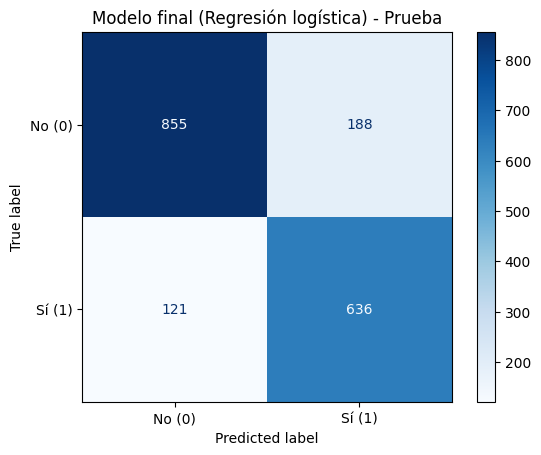

In [ ]:
evaluar(mejor_lr, X_test, y_test, 'Modelo final (Regresión logística) - Prueba')

### 6.4 Variables más influyentes

Una ventaja de la regresión logística es que sus coeficientes indican qué variables aumentan (coeficiente positivo) o disminuyen (coeficiente negativo) la probabilidad de que el cliente adquiera el plan.

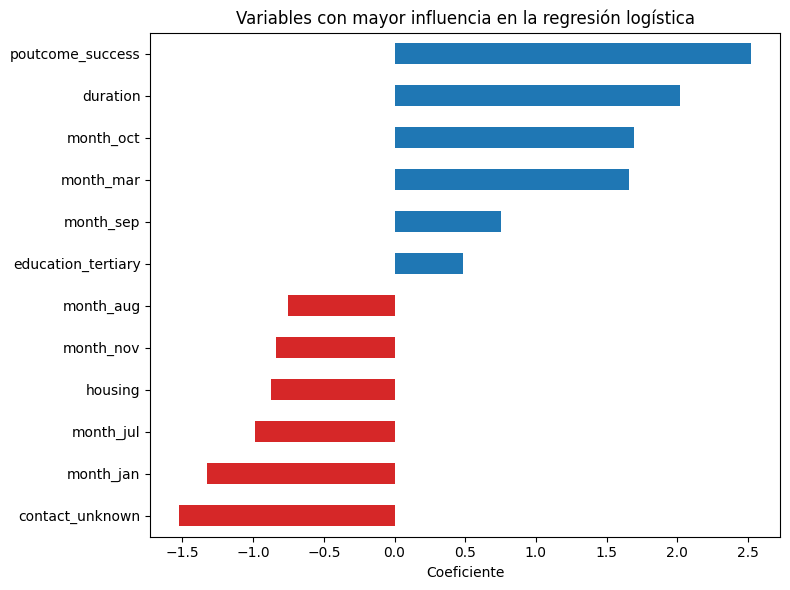

In [ ]:
coeficientes = pd.Series(mejor_lr.coef_[0], index=X.columns).sort_values()

top = pd.concat([coeficientes.head(6), coeficientes.tail(6)])
top.plot(kind='barh', figsize=(8, 6),
         color=['tab:red' if c < 0 else 'tab:blue' for c in top])
plt.title('Variables con mayor influencia en la regresión logística')
plt.xlabel('Coeficiente')
plt.tight_layout()
plt.show()

## 7. Conclusiones

**Desempeño final.** La regresión logística obtuvo una exactitud de **82.83%** en el conjunto de prueba, muy similar a la de validación (83.56%), lo que confirma que el modelo generaliza bien a datos nuevos. De los 757 clientes de prueba que sí adquirieron el plan, el modelo identificó correctamente a 636 (recall de **84%**). La matriz de confusión muestra 855 verdaderos negativos, 636 verdaderos positivos, 188 falsos positivos y 121 falsos negativos.

**Características de los clientes más propensos.** Según los coeficientes del modelo:
- Los clientes con **éxito en una campaña anterior** (`poutcome_success`) son los más propensos a adquirir el plan.
- Una **mayor duración de la llamada** se asocia fuertemente con la compra.
- Los contactos en **marzo, septiembre y octubre** tienen mayor probabilidad de éxito; enero, julio, agosto y noviembre, menor.
- Tener un **crédito hipotecario** (`housing`) y un **medio de contacto desconocido** reducen la probabilidad.

Una observación importante: la duración de la llamada solo se conoce cuando la llamada ya terminó, por lo que sirve para entender el comportamiento del cliente, pero no para decidir a quién llamar antes de hacerlo.

**Uso de la inteligencia artificial en mercadotecnia.** Este problema muestra que las técnicas de aprendizaje supervisado permiten aprovechar los datos históricos de campañas anteriores para predecir qué clientes tienen más probabilidad de responder positivamente. En lugar de llamar a todos los clientes por igual, el banco puede **priorizar** a quienes el modelo identifica como más propensos, reduciendo costos de operación y mejorando la tasa de conversión. Además, modelos interpretables como la regresión logística ayudan a entender el perfil del cliente ideal y a decidir mejor el momento y el canal de contacto. Sin embargo, el modelo no sustituye el criterio del equipo de mercadotecnia: debe actualizarse con datos nuevos y usarse como apoyo para tomar decisiones, cuidando además el uso responsable de la información personal de los clientes.